In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet('/content/drive/MyDrive/master_df_clean.parquet')
df.head()

,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,abs_amount,target,target_numeric,amount_bins
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,None,77.00,No,0.0,"(-100, 0]"
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,None,14.57,No,0.0,"(0, 50]"
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,92084.0,4829,None,80.00,No,0.0,"(50, 100]"
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,46307.0,4829,None,200.00,None,NaN,"(100, 200]"
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,20776.0,5813,None,46.41,No,0.0,"(0, 50]"


In [3]:
df['amount_bins'] = df['amount_bins'].astype('category')

In [4]:
df.columns

Index(['id', 'date', 'time', 'client_id', 'card_id', 'amount', 'use_chip',
       'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc',
       'errors', 'abs_amount', 'target', 'target_numeric', 'amount_bins'],
      dtype='object')

In [5]:
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['amount'] < lower_bound) | (df['amount'] > upper_bound)]

print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
print(f"Total Outliers detected: {len(outliers)}")
print(f"Percentage of Outliers: {100 * len(outliers) / len(df):.2f}%")

display(outliers.head())

Lower Bound: -73.23999786376953
Upper Bound: 145.87999725341797
Total Outliers detected: 1052611
Percentage of Outliers: 7.91%


,id,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,abs_amount,target,target_numeric,amount_bins
0,7475327,2010-01-01,00:01:00,1556,2972,-77.000000,Swipe Transaction,59935,Beulah,ND,58523.0,5499,None,77.000000,No,0.0,"(-100, 0]"
3,7475331,2010-01-01,00:05:00,430,2860,200.000000,Swipe Transaction,27092,Crown Point,IN,46307.0,4829,None,200.000000,None,NaN,"(100, 200]"
8,7475336,2010-01-01,00:21:00,335,5131,261.579987,Online Transaction,50292,Online,None,NaN,7801,None,261.579987,None,NaN,"(200, 500]"
28,7475358,2010-01-01,00:48:00,401,3004,669.880005,Swipe Transaction,68977,West Covina,CA,91791.0,3174,None,669.880005,None,NaN,"(500, 1000]"
35,7475365,2010-01-01,01:01:00,820,127,270.220001,Online Transaction,73186,Online,None,NaN,4814,None,270.220001,No,0.0,"(200, 500]"


# Multivariate Analysis

### amount vs use_chip vs target

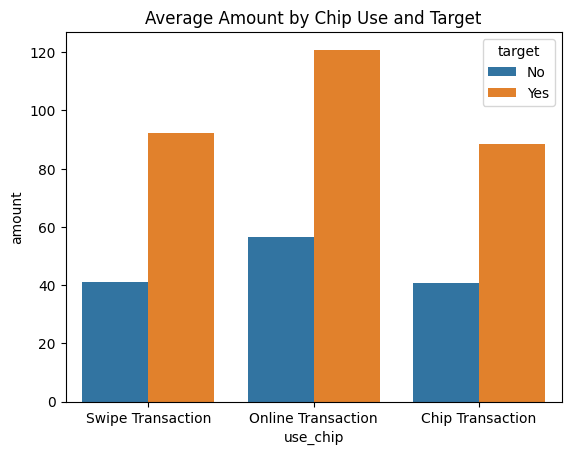

In [6]:
sns.barplot(data=df, x='use_chip', y='amount', hue='target', errorbar=None)
plt.title('Average Amount by Chip Use and Target')
plt.show()

- Online fraudulent transactions have the highest average transaction value (~120), indicating that high-value online purchases represent a particularly risky transaction segment.

### mcc vs use_chip vs target

In [7]:
temp = (
    df.groupby(['mcc', 'use_chip'], dropna=True)['target_numeric']
    .agg(['mean', 'count'])
    .reset_index()
)

temp = temp[temp['count'] > 1000]

temp['fraud_rate'] = temp['mean'] * 100

temp.sort_values(
    'fraud_rate',
    ascending=False
).head(10)

,mcc,use_chip,mean,count,fraud_rate
185,5732,Online Transaction,0.262467,1524,26.246719
129,5045,Online Transaction,0.095473,1215,9.547325
131,5094,Chip Transaction,0.063325,1516,6.332454
198,5816,Online Transaction,0.057869,1849,5.786912
205,5932,Chip Transaction,0.036993,1676,3.699284
169,5651,Online Transaction,0.029438,5639,2.943784
258,7996,Online Transaction,0.023986,3919,2.398571
113,4511,Online Transaction,0.019864,1913,1.986409
138,5193,Online Transaction,0.019455,3341,1.945525
178,5712,Swipe Transaction,0.019260,1298,1.926040


- Fraud risk is significantly elevated for online transactions in electronics, computer-related, and digital goods categories, while high-value specialty merchants remain vulnerable regardless of payment method.

### merchant_state vs use_chip vs target

In [8]:
ms_temp = df.groupby(['merchant_state', 'use_chip'], dropna=True)['target_numeric'].agg(['mean', 'count']).reset_index()

ms_temp = ms_temp[ms_temp['count'] > 1000]
ms_temp['fraud_rate'] = ms_temp['mean'] * 100
display(ms_temp.sort_values(by='fraud_rate', ascending=False).head(10))

,merchant_state,use_chip,mean,count,fraud_rate
134,Italy,Chip Transaction,0.786339,3543,78.633926
135,Italy,Swipe Transaction,0.236457,1163,23.645744
232,OH,Swipe Transaction,0.001484,192038,0.148408
116,IA,Swipe Transaction,0.000451,62058,0.045119
266,SD,Swipe Transaction,0.000410,12189,0.041021
265,SD,Chip Transaction,0.000345,8686,0.034538
346,WY,Swipe Transaction,0.000294,3399,0.029420
105,HI,Chip Transaction,0.000285,21088,0.028452
175,MO,Swipe Transaction,0.000271,81081,0.027133
233,OK,Chip Transaction,0.000251,39807,0.025121


- Italy is the primary fraud hotspot, with Chip Transactions showing an exceptionally high fraud rate (78.63%) and Swipe Transactions also exhibiting elevated fraud risk (23.65%).

### use_chip vs amount_bins vs target

In [9]:
ab_temp = df.groupby(['use_chip', 'amount_bins'])['target_numeric'].agg(
    ['mean', 'count']
).reset_index()

ab_temp = ab_temp[ab_temp['count']>1000]
ab_temp['fraud_rate'] = ab_temp['mean']*100

ab_temp.sort_values(by='fraud_rate', ascending=False).reset_index(drop=True).head(10)

/tmp/ipykernel_893/930625841.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ab_temp = df.groupby(['use_chip', 'amount_bins'])['target_numeric'].agg(


,use_chip,amount_bins,mean,count,fraud_rate
0,Online Transaction,"(-500, -100]",0.090970,4452,9.097035
1,Online Transaction,"(1000, 2000]",0.052316,1166,5.231561
2,Online Transaction,"(500, 1000]",0.040595,4237,4.059476
3,Online Transaction,"(200, 500]",0.036295,38297,3.629527
4,Online Transaction,"(100, 200]",0.020743,103844,2.074265
5,Online Transaction,"(50, 100]",0.010961,170155,1.096059
6,Chip Transaction,"(500, 1000]",0.008541,7142,0.854102
7,Chip Transaction,"(200, 500]",0.005396,57269,0.539559
8,Chip Transaction,"(1000, 2000]",0.004562,1973,0.456158
9,Online Transaction,"(0, 50]",0.003745,721701,0.374532


- Online refund transactions (-500 to -100) exhibit the highest observed fraud rate (9.10%), suggesting a potentially risky transaction segment
- Online transactions become significantly riskier as transaction value increases, with fraud rates rising from 0.37% (\$0–50) to 5.23% ($1000–2000)

In [10]:
error_stats = (
    df.groupby('errors', dropna=True)['target_numeric']
    .agg(['mean','count'])
    .reset_index()
)

error_stats['fraud_rate'] = error_stats['mean'] * 100

error_stats.sort_values(
    'fraud_rate',
    ascending=False
).head(10)

,errors,mean,count,fraud_rate
2,"Bad CVV,Technical Glitch",0.200000,5,20.000000
1,"Bad CVV,Insufficient Balance",0.050000,40,5.000000
0,Bad CVV,0.033977,4091,3.397702
7,"Bad Card Number,Insufficient Balance",0.020000,50,2.000000
9,Bad Expiration,0.013216,4086,1.321586
3,Bad Card Number,0.011270,5235,1.127030
13,Bad PIN,0.005212,21488,0.521221
14,"Bad PIN,Insufficient Balance",0.005051,198,0.505051
19,Insufficient Balance,0.001927,87686,0.192733
21,Technical Glitch,0.001744,17776,0.174392


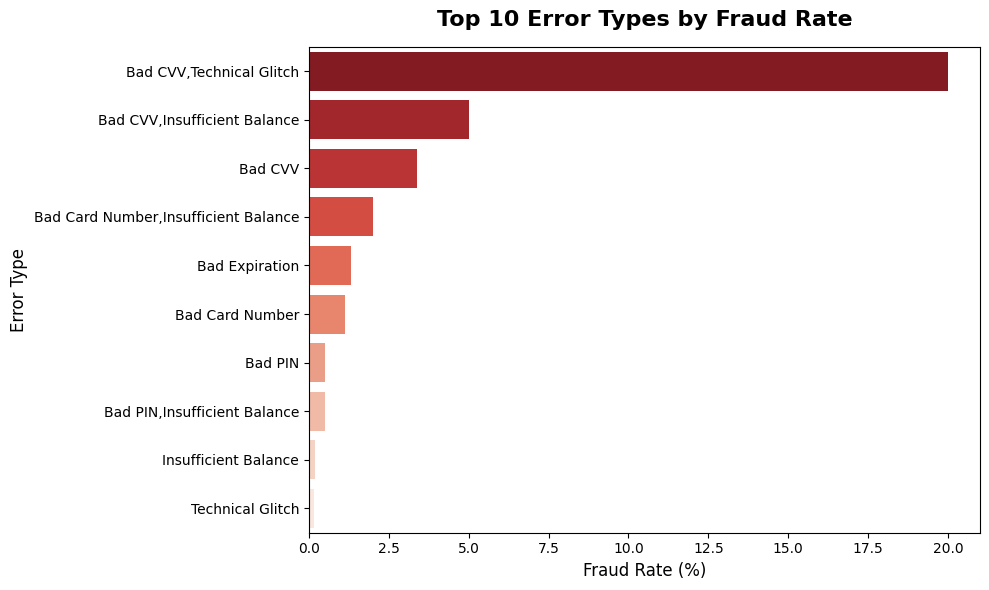

In [11]:
top_errors = error_stats.sort_values('fraud_rate', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    x='fraud_rate',
    y='errors',
    data=top_errors,
    ax=ax,
    palette='Reds_r',
    hue='errors',
    legend=False
)

ax.set_title('Top 10 Error Types by Fraud Rate', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Fraud Rate (%)', fontsize=12)
ax.set_ylabel('Error Type', fontsize=12)
plt.tight_layout()

* **Bad CVV is the strongest error-related fraud signal**, with a fraud rate of **3.40%**, significantly higher than the overall dataset fraud rate (~0.15%).

* **Card validation failures (Bad CVV, Bad Expiration, Bad Card Number)** consistently exhibit elevated fraud rates, suggesting that authentication-related errors are strongly associated with fraudulent activity.


### error vs use_chip vs target

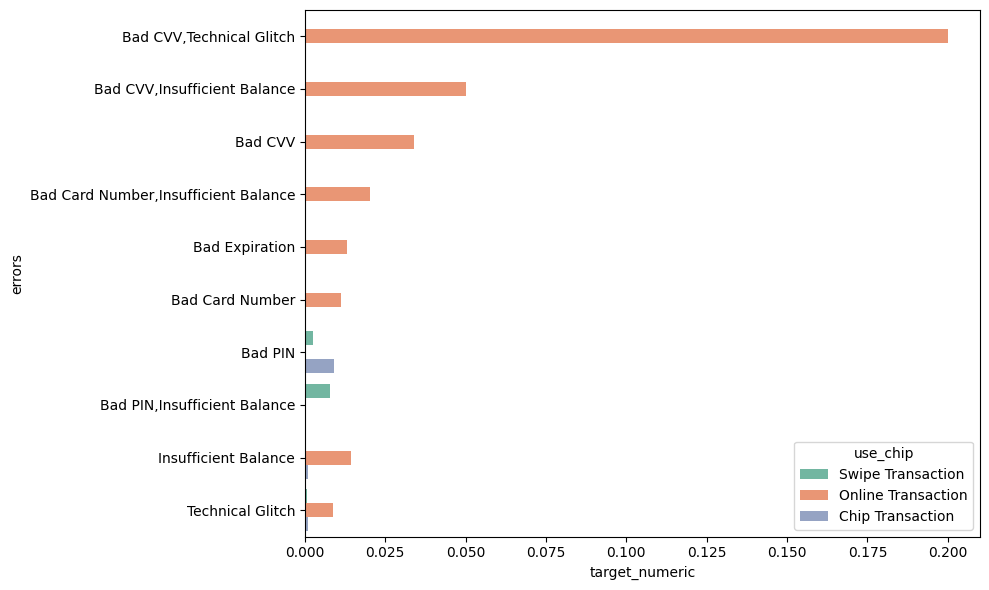

In [12]:
error_order = df.groupby('errors')['target_numeric'].mean().sort_values(ascending=False).head(10).index

plt.subplots(figsize=(10, 6))

sns.barplot(
    x='target_numeric',
    y='errors',
    hue='use_chip',
    data=df,
    order=error_order,
    estimator='mean',
    errorbar=None,
    palette='Set2',
)
plt.tight_layout()
plt.show()

In [13]:
mcc_stats = (
    df.groupby(['mcc', 'amount_bins'], dropna=True, observed=False)['target_numeric']
    .agg(['mean','count'])
    .reset_index()
)

mcc_stats['fraud_rate'] = mcc_stats['mean'] * 100


mcc_top = mcc_stats[mcc_stats['count'] > 500].sort_values(
    'fraud_rate',
    ascending=False
).head(10)

display(mcc_top)

,mcc,amount_bins,mean,count,fraud_rate
740,5732,"(100, 200]",0.163472,887,16.347238
742,5732,"(200, 500]",0.083846,1300,8.384615
709,5712,"(200, 500]",0.069351,894,6.935123
744,5732,"(50, 100]",0.067260,1011,6.726014
739,5732,"(0, 50]",0.054922,1402,5.492154
511,5045,"(200, 500]",0.053492,673,5.349183
610,5311,"(200, 500]",0.053469,3834,5.346896
599,5310,"(200, 500]",0.052895,1796,5.289532
808,5816,"(200, 500]",0.045911,697,4.591105
519,5094,"(0, 50]",0.044433,2003,4.443335


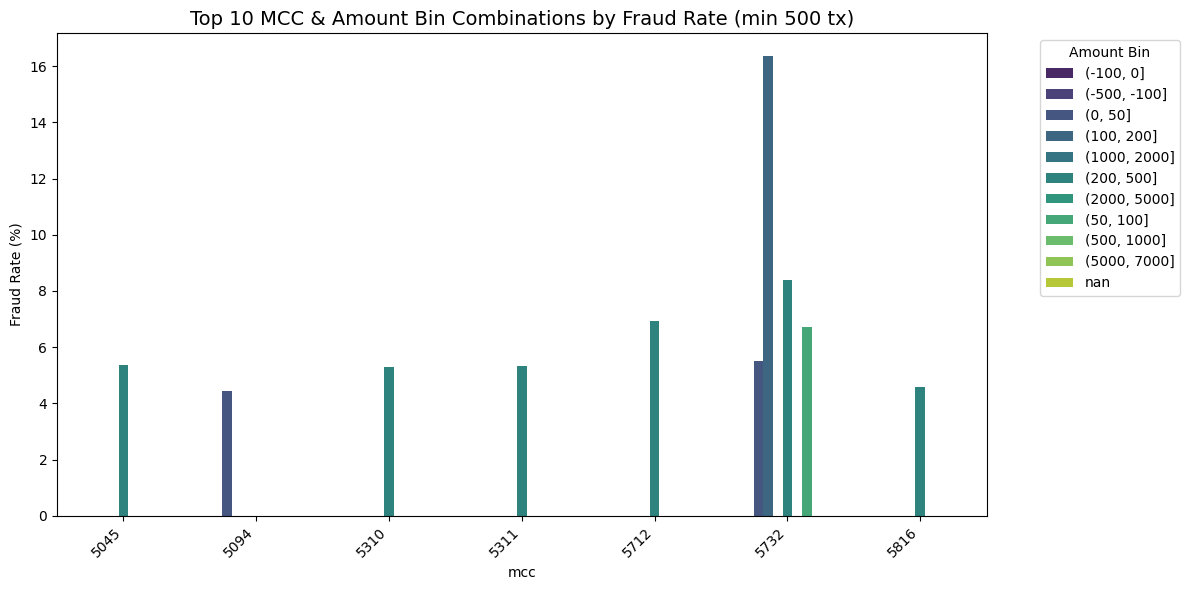

In [14]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=mcc_top,
    x='mcc',
    y='fraud_rate',
    hue='amount_bins',
    palette='viridis'
)

plt.title('Top 10 MCC & Amount Bin Combinations by Fraud Rate (min 500 tx)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Fraud Rate (%)')
plt.legend(title='Amount Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

- Fraud risk is highest when high-value transactions occur in technology, digital goods, and retail-related merchant categories, suggesting that merchant type and transaction amount together provide strong predictive signals.

# Importing User and Card Data

In [15]:
user_df = pd.read_csv('/content/drive/MyDrive/Machine Learning/Projects/Fraud Detection Capstone Project/Datasets/Cleaned Dataset/cleaned_user_data.csv')
user_df.head()

,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,29278.0,59696.0,127613.0,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,37891.0,77254.0,191349.0,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,22681.0,33483.0,196.0,698,5
3,708,63,63,1957,1,Female,3 Madison Street,40.71,-73.99,163145.0,249925.0,202328.0,722,4
4,1164,43,70,1976,9,Male,9620 Valley Stream Drive,37.76,-122.44,53797.0,109687.0,183855.0,675,1


In [16]:
def downcast_dtypes(df, money_cols=None, skip_cols=None):
    money_cols = money_cols or []
    skip_cols = skip_cols or []

    for col in df.columns:
        if col in skip_cols or df[col].dtype.name in ('category',) or pd.api.types.is_datetime64_any_dtype(df[col]):
            continue
        if col in money_cols:
            df[col] = df[col].astype('float32')
        elif pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='integer')
        elif pd.api.types.is_float_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='float')
    return df

master_df = downcast_dtypes(user_df, money_cols=['per_capita_income', 'yearly_income', 'total_debt'])

In [17]:
master_df =  df.merge(user_df, how='left', left_on='client_id', right_on='id')

print(f"New shape: {df.shape}")
master_df.head()

New shape: (13305915, 17)


,id_x,date,time,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,...,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,7475327,2010-01-01,00:01:00,1556,2972,-77.00,Swipe Transaction,59935,Beulah,ND,...,7,Female,594 Mountain View Street,46.799999,-100.760002,23679.0,48277.0,110153.0,740,4
1,7475328,2010-01-01,00:02:00,561,4575,14.57,Swipe Transaction,67570,Bettendorf,IA,...,6,Male,604 Pine Street,40.799999,-91.120003,18076.0,36853.0,112139.0,834,5
2,7475329,2010-01-01,00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,...,4,Male,2379 Forest Lane,33.180000,-117.290001,16894.0,34449.0,36540.0,686,3
3,7475331,2010-01-01,00:05:00,430,2860,200.00,Swipe Transaction,27092,Crown Point,IN,...,5,Female,903 Hill Boulevard,41.419998,-87.349998,26168.0,53350.0,128676.0,685,5
4,7475332,2010-01-01,00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,...,5,Male,166 River Drive,38.860001,-76.599998,33529.0,68362.0,96182.0,711,2


In [18]:
import gc
vars_to_del = ['user_df']

for var in vars_to_del:
    if var in globals():
        del globals()[var]

gc.collect()

print("RAM cleared.")

RAM cleared.


In [19]:
master_df.columns

Index(['id_x', 'date', 'time', 'client_id', 'card_id', 'amount', 'use_chip',
       'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc',
       'errors', 'abs_amount', 'target', 'target_numeric', 'amount_bins',
       'id_y', 'current_age', 'retirement_age', 'birth_year', 'birth_month',
       'gender', 'address', 'latitude', 'longitude', 'per_capita_income',
       'yearly_income', 'total_debt', 'credit_score', 'num_credit_cards'],
      dtype='object')

In [20]:
master_df = master_df.drop(columns=['id_y'])
master_df = master_df.rename(columns={'id_x': 'id'})

# Univariate Analysis (User data)

In [21]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [22]:
master_df.iloc[:,16:].describe()

,current_age,retirement_age,birth_year,birth_month,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
count,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00,13305915.00
mean,54.03,66.49,1965.16,6.57,37.38,-91.57,23979.68,46683.67,58022.12,713.91,3.84
std,15.73,3.59,15.72,3.61,5.57,16.06,11808.71,24038.36,51682.82,65.80,1.57
min,23.00,53.00,1918.00,1.00,21.30,-158.18,0.00,1.00,0.00,488.00,1.00
25%,42.00,65.00,1956.00,3.00,33.89,-97.37,17113.00,32817.00,16437.00,684.00,3.00
50%,52.00,66.00,1968.00,7.00,38.35,-86.47,21156.00,41069.00,51679.00,716.00,4.00
75%,63.00,68.00,1977.00,10.00,41.12,-80.12,27308.00,54013.00,85160.00,756.00,5.00
max,101.00,79.00,1996.00,12.00,48.53,-68.67,163145.00,280199.00,461854.00,850.00,9.00


In [23]:
master_df.iloc[:,16:].isna().sum()

,0
amount_bins,0
current_age,0
retirement_age,0
birth_year,0
birth_month,0
gender,0
address,0
latitude,0
longitude,0
per_capita_income,0


### current_age

In [24]:
master_df['current_age'].skew()

np.float64(0.5476134578977008)

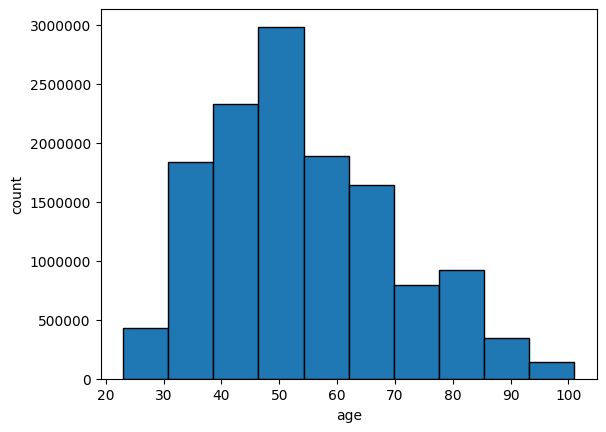

In [25]:
plt.hist(master_df['current_age'], edgecolor='black')
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('age')
plt.ylabel('count')
plt.show()

##

In [26]:
master_df['retirement_age'].skew()

np.float64(-0.32129617806189986)

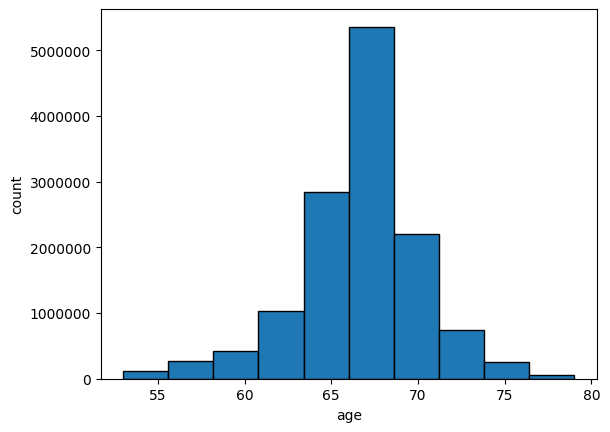

In [27]:
plt.hist(master_df['retirement_age'], edgecolor='black')
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('age')
plt.ylabel('count')
plt.show()

In [28]:
master_df['gender'].value_counts(normalize=True)

,proportion
gender,
Female,0.51
Male,0.49


In [29]:
master_df['per_capita_income'].skew()

np.float32(3.717988)

<Axes: xlabel='per_capita_income', ylabel='Count'>

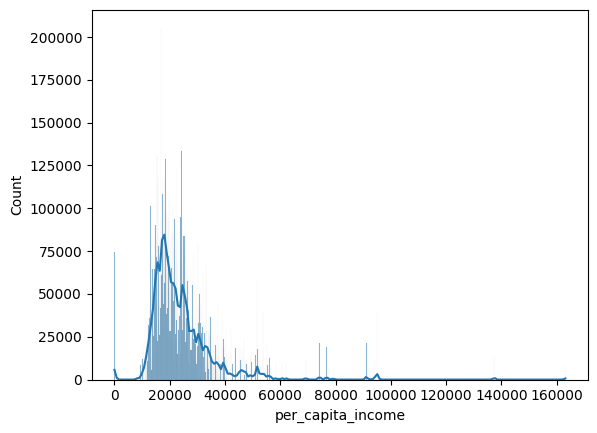

In [30]:
sns.histplot(master_df['per_capita_income'],kde=True)

<Axes: ylabel='per_capita_income'>

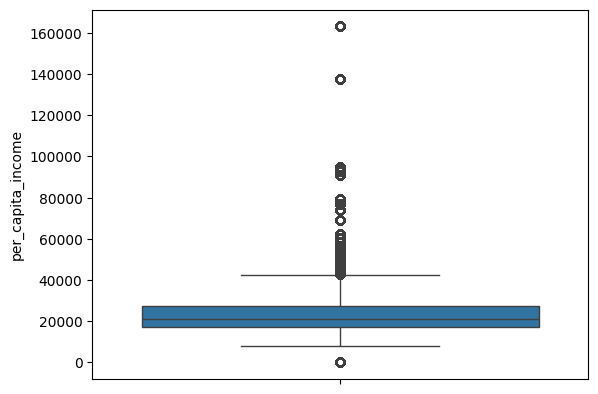

In [31]:
sns.boxplot(master_df['per_capita_income'])

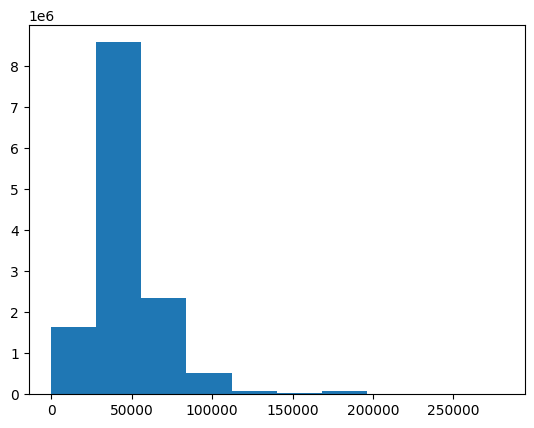

In [35]:
plt.hist(master_df['yearly_income'])
plt.show()

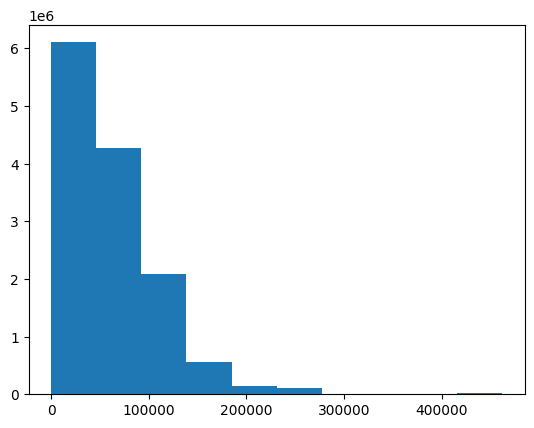

In [36]:
plt.hist(master_df['total_debt'])
plt.show()

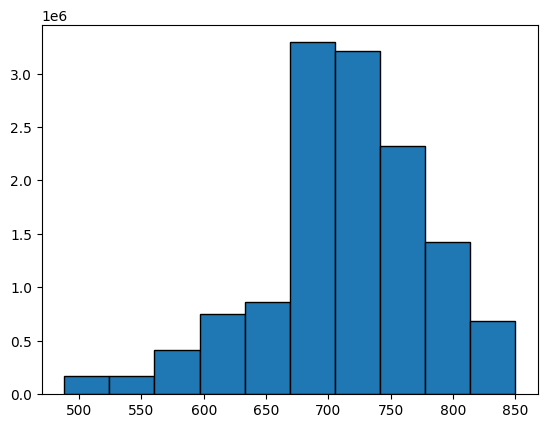

In [37]:
plt.hist(master_df['credit_score'], edgecolor='black')
plt.show()

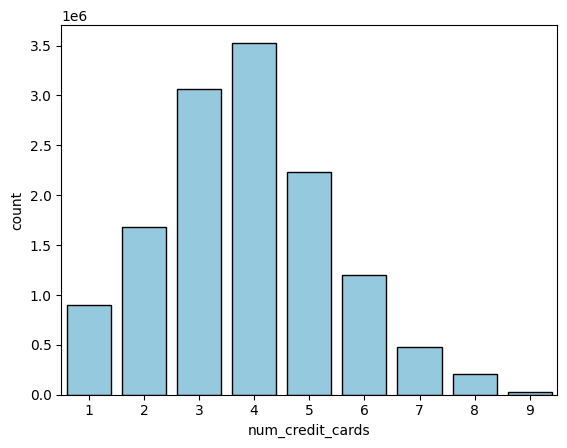

In [41]:
sns.countplot(x=master_df['num_credit_cards'], color='skyblue', edgecolor='black')
plt.show()

# Bivariate Analysis

### credit score vs target

In [42]:
master_df.groupby('target')['credit_score'].mean()

,credit_score
target,
No,713.92
Yes,715.33


- Average credit scores are nearly identical for fraudulent and non-fraudulent transactions, indicating that credit score alone is not a strong fraud indicator in this dataset.

/tmp/ipykernel_893/3382363781.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_fraud = master_df.groupby('age_group')['target_numeric'].mean() * 100


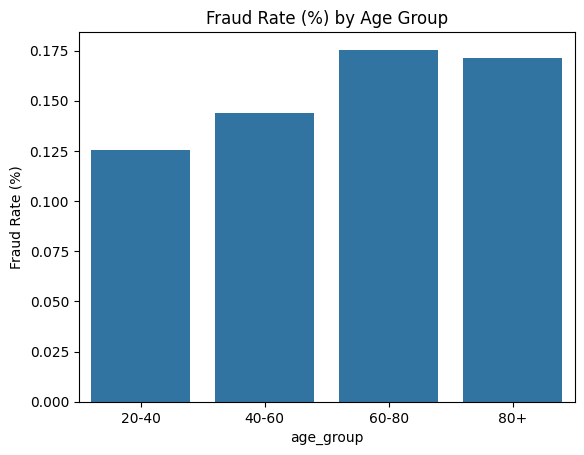

In [51]:
master_df['age_group'] = pd.cut(master_df['current_age'], bins=[20, 40, 60, 80, 110], labels=['20-40', '40-60', '60-80', '80+'])

age_fraud = master_df.groupby('age_group')['target_numeric'].mean() * 100
sns.barplot(x=age_fraud.index, y=age_fraud.values, legend=False)
plt.title('Fraud Rate (%) by Age Group')
plt.ylabel('Fraud Rate (%)')
plt.show()

- Fraud rates increase with age, rising from 0.13% for users aged 20–40 to 0.18% for users aged 60–80, suggesting older customers are slightly more susceptible to fraudulent transactions.

/tmp/ipykernel_893/2319703200.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_fraud = master_df.groupby('income_group')['target_numeric'].mean() * 100


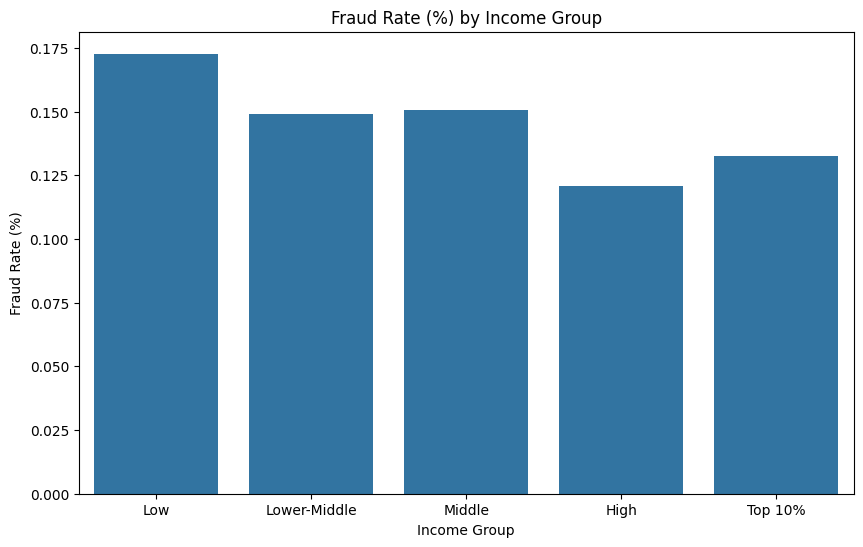

In [52]:
income_labels = ['Low', 'Lower-Middle', 'Middle', 'High', 'Top 10%']
master_df['income_group'] = pd.qcut(master_df['yearly_income'], q=[0, 0.25, 0.50, 0.75, 0.90, 1.0], labels=income_labels)

income_fraud = master_df.groupby('income_group')['target_numeric'].mean() * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=income_fraud.index, y=income_fraud.values, legend=False)
plt.title('Fraud Rate (%) by Income Group')
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Income Group')
plt.show()

- Lower-income users exhibit the highest fraud rates (\~0.17%), while the high-income group has the lowest fraud rate (~0.12%)
- The differences across income groups are relatively small, indicating that income alone is not a major fraud driver

In [ ]:
sns.barplot(master_df, x='gender', )

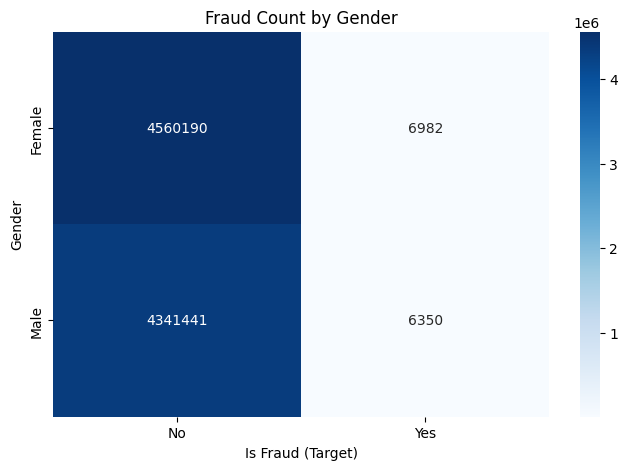

In [55]:
plt.figure(figsize=(8, 5))
ct = pd.crosstab(master_df['gender'], master_df['target'])
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Fraud Count by Gender')
plt.ylabel('Gender')
plt.xlabel('Is Fraud (Target)')
plt.show()

- Fraud can happen irrespective of the users gender

### num_credit_cards vs target

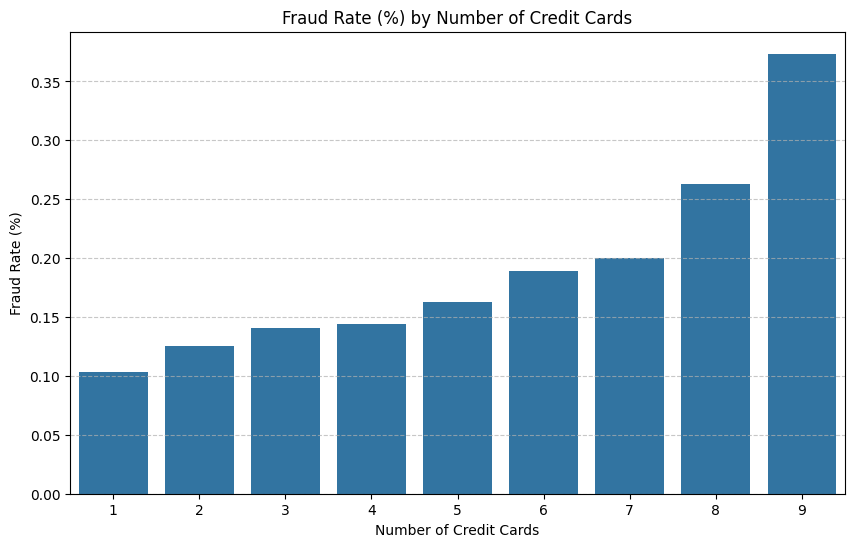

Fraud Rate by Number of Credit Cards:
num_credit_cards
1   0.10
2   0.13
3   0.14
4   0.14
5   0.16
6   0.19
7   0.20
8   0.26
9   0.37
Name: target_numeric, dtype: float64


In [56]:
card_count_fraud = master_df.groupby('num_credit_cards')['target_numeric'].mean() * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=card_count_fraud.index, y=card_count_fraud.values, legend=False)
plt.title('Fraud Rate (%) by Number of Credit Cards')
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Number of Credit Cards')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

- Fraud rate increases steadily with the number of credit cards owned, rising from 0.10% (1 card) to 0.37% (9 cards), indicating that customers managing multiple cards experience higher fraud exposure.
- Users with 8–9 credit cards exhibit more than double the fraud rate of users with only 1–2 cards, suggesting that the number of credit cards is a meaningful fraud risk indicator.

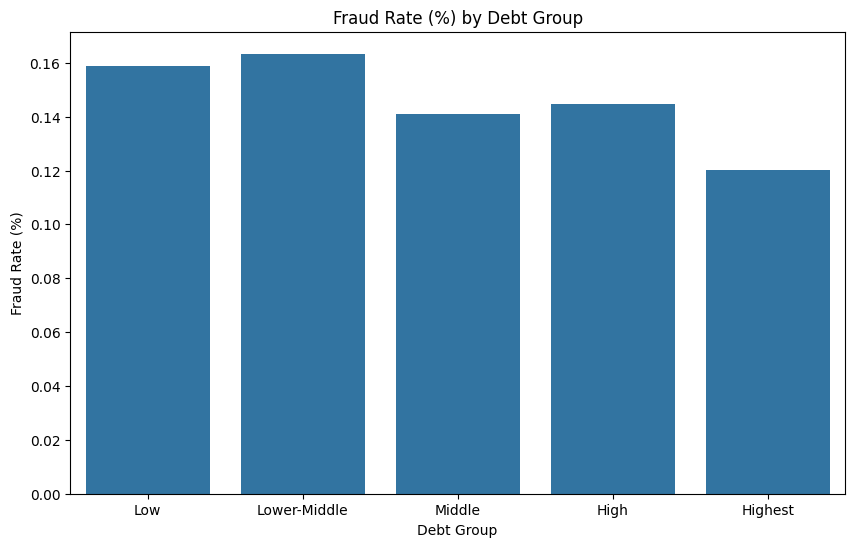

In [71]:
debt_labels = ['Low', 'Lower-Middle', 'Middle', 'High', 'Highest']
master_df['debt_group'] = pd.qcut(master_df['total_debt'], q=[0, 0.25, 0.50, 0.75, 0.90, 1.0], labels=debt_labels)


debt_fraud = master_df.groupby('debt_group', observed=False)['target_numeric'].mean() * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=debt_fraud.index, y=debt_fraud.values, legend=False)
plt.title('Fraud Rate (%) by Debt Group')
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Debt Group')
plt.show()

In [69]:
master_df['total_debt']

,total_debt
0,110153.00
1,112139.00
2,36540.00
3,128676.00
4,96182.00
...,...
13305910,196.00
13305911,12092.00
13305912,40161.00
13305913,62384.00


In [57]:
master_df.columns

Index(['id', 'date', 'time', 'client_id', 'card_id', 'amount', 'use_chip',
       'merchant_id', 'merchant_city', 'merchant_state', 'zip', 'mcc',
       'errors', 'abs_amount', 'target', 'target_numeric', 'amount_bins',
       'current_age', 'retirement_age', 'birth_year', 'birth_month', 'gender',
       'address', 'latitude', 'longitude', 'per_capita_income',
       'yearly_income', 'total_debt', 'credit_score', 'num_credit_cards',
       'age_group', 'income_group'],
      dtype='object')

# Multivariate Analysis

### num_credit_cards vs use_chip vs target

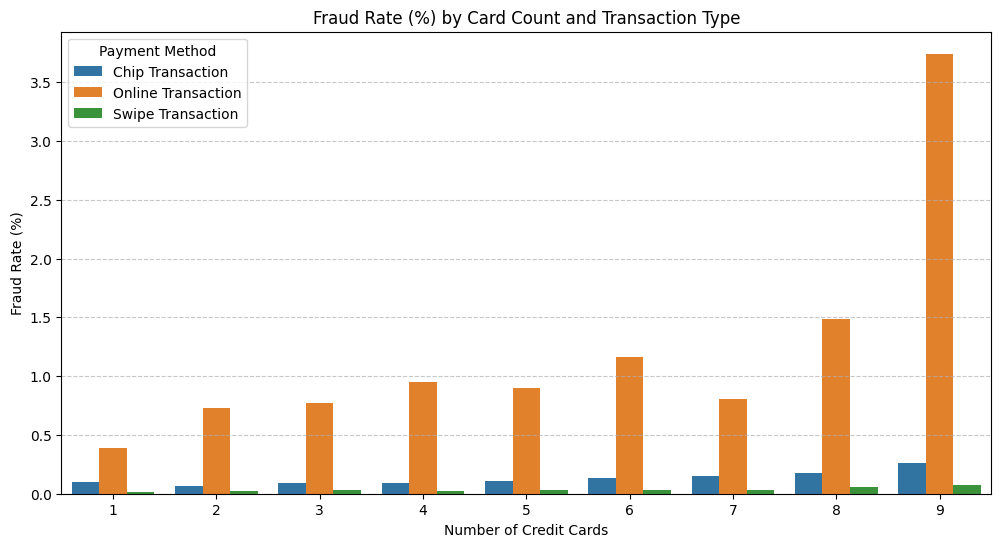

In [62]:
credit_chip_df = master_df.groupby(['num_credit_cards', 'use_chip'])['target_numeric'].mean().reset_index()
credit_chip_df['fraud_rate'] = credit_chip_df['target_numeric'] * 100

plt.figure(figsize=(12, 6))
sns.barplot(data=credit_chip_df, x='num_credit_cards', y='fraud_rate', hue='use_chip')
plt.title('Fraud Rate (%) by Card Count and Transaction Type')
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Number of Credit Cards')
plt.legend(title='Payment Method')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

- As we found earlier, online transaction and more no. of chips has more fraud volume

In [72]:
master_df.to_parquet('/content/drive/MyDrive/Machine Learning/master_df_merged.parquet')